# Day 31 — What Machine Learning Actually Is
### Module 3 · Machine Learning · Topics 3.1 + 3.2

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

## Read this first

This is your **first machine learning notebook**. It starts from zero.

**You do not need to remember anything from earlier classes.** Every idea is explained the
moment it appears, every cell is short, and every example is something you can picture.

| § | Section | The question it answers |
|---|---|---|
| 1 | Why machine learning | Why can't we just write the rules ourselves? |
| 2 | How a model learns | What is actually happening when a computer "learns"? |
| 3 | The three families | What kinds of problems can machine learning solve? |
| 4 | Words into numbers | A model only does arithmetic. So what about "Dell"? |
| 5 | Put it together | What does the whole thing look like in code? |

**How to use it:** run every cell, in order, top to bottom. Then **change the numbers and
run it again** — that is how this actually goes in. Nothing here can break.

---
## Setting up

One cell to load the tools. Run it and forget about it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

import warnings
warnings.simplefilter("ignore")        # hides harmless technical messages

plt.rcParams["figure.figsize"] = (8, 3.4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Ready. Move on to Part 1.")

Ready. Move on to Part 1.


---
# Part 1 · Why machine learning exists

## 1.1 · Your job: stop spam

Imagine you work at an email company. Your task is to write the rules that decide whether
an email is spam.

Let us try the most obvious rule: **flag it if it contains "free", "won", or "urgent".**

In [2]:
emails = [
    ("WIN a FREE iPhone now!!!",           "spam"),
    ("Free pizza in the lab at 5pm",       "not spam"),
    ("Congratulations, you won a lottery", "spam"),
    ("Your exam results are out",          "not spam"),
    ("URGENT: verify your bank details",   "spam"),
    ("Urgent: assignment due tomorrow",    "not spam"),
]

def my_rule(text):
    """Our hand-written spam rule."""
    t = text.lower()
    if "free" in t or "won" in t or "urgent" in t:
        return "spam"
    return "not spam"

print(f"{'the email':<38} {'rule says':<10} {'truth':<10} ")
print("-" * 68)
correct = 0
for text, truth in emails:
    guess = my_rule(text)
    ok = guess == truth
    correct += ok
    print(f"{text:<38} {guess:<10} {truth:<10} {'correct' if ok else 'WRONG'}")

print(f"\nScore: {correct} right out of {len(emails)}")

the email                              rule says  truth      
--------------------------------------------------------------------
WIN a FREE iPhone now!!!               spam       spam       correct
Free pizza in the lab at 5pm           spam       not spam   WRONG
Congratulations, you won a lottery     spam       spam       correct
Your exam results are out              not spam   not spam   correct
URGENT: verify your bank details       spam       spam       correct
Urgent: assignment due tomorrow        spam       not spam   WRONG

Score: 4 right out of 6


### Look at the two it got wrong

- **"Free pizza in the lab at 5pm"** — a genuine message, sent to the spam folder.
- **"Urgent: assignment due tomorrow"** — also genuine, also binned.

Those are the worst kind of mistake. Nobody minds a spam email slipping through; everybody
minds missing a real one.

### So you add an exception. And another.

In [3]:
def my_rule_v2(text):
    t = text.lower()
    if "pizza" in t or "assignment" in t:      # the exceptions we just added
        return "not spam"
    if "free" in t or "won" in t or "urgent" in t:
        return "spam"
    return "not spam"

correct = sum(my_rule_v2(t) == truth for t, truth in emails)
print(f"Score now: {correct} out of {len(emails)}")
print()
print("6 out of 6! ...but we did not teach it anything.")
print("We just hard-coded the two emails it failed on.")

Score now: 6 out of 6

6 out of 6! ...but we did not teach it anything.
We just hard-coded the two emails it failed on.


### And this is where it falls apart

Spammers adapt. They write **F-R-E-E**, or **FR33**, or **"no cost"**. Each one needs
another rule. The rules start contradicting each other. After a few hundred, nobody can
safely change the code any more.

**The problem is not that you are a bad programmer.** The problem is that nobody actually
knows the rule for "is this spam". You recognise spam instantly, but you cannot write down
how you did it.

## 1.2 · The flip

So stop writing rules. **Show the computer examples instead.**

| | You give it | It gives you back |
|---|---|---|
| **Ordinary programming** | the rules + the data | the answers |
| **Machine learning** | the data + the answers | **the rules** |

Same three things. The arrows point the other way. **That is the entire idea of machine
learning**, and everything else is detail.

## 1.3 · The words we will use

Look at this table. Four laptops, and what each one sold for.

In [4]:
laptops = pd.DataFrame({
    "brand":  ["Dell", "HP", "Apple", "Asus"],
    "ram_gb": [8, 16, 8, 4],
    "screen": [14.0, 15.6, 13.3, 14.0],
    "age_yr": [2, 1, 3, 4],
    "price":  [34, 52, 71, 21],          # thousands of rupees
})
laptops

,brand,ram_gb,screen,age_yr,price
0,Dell,8,14.0,2,34
1,HP,16,15.6,1,52
2,Apple,8,13.3,3,71
3,Asus,4,14.0,4,21


Four words, used constantly from now on:

| Word | What it means here |
|---|---|
| **sample** | one **row** — one laptop |
| **feature** | one **input column** — brand, ram_gb, screen, age_yr |
| **label** | the **answer column** we want to predict — price |
| **model** | the rule the computer finds, connecting features to label |

So this table has **4 samples, 4 features and 1 label**.

Almost every dataset in this course looks exactly like this. Get comfortable with the shape
now and the rest of the module is much easier.

In [5]:
print("samples (rows)    :", laptops.shape[0])
print("columns in total  :", laptops.shape[1])
print("features (inputs) :", laptops.shape[1] - 1)
print("label  (the answer):", "price")

samples (rows)    : 4
columns in total  : 5
features (inputs) : 4
label  (the answer): price


---
# Part 2 · How a model actually learns

People talk about machine learning as if something mysterious happens. It does not. Let us
watch the whole thing on five phones.

## 2.1 · A model is just a few numbers we can change

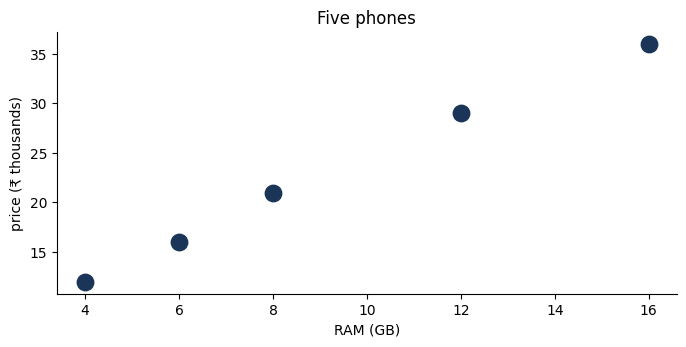

In [5]:
ram   = np.array([4, 6, 8, 12, 16])        # GB of RAM
price = np.array([12, 16, 21, 29, 36])     # price in thousands of rupees

plt.scatter(ram, price, s=140, color="#1B3558")
plt.xlabel("RAM (GB)"); plt.ylabel("price (₹ thousands)")
plt.title("Five phones")
plt.show()

More RAM clearly costs more. The question is **exactly how much more**.

Our model will be:

$$\text{price} \;=\; A \;+\; B \times \text{RAM}$$

**A** and **B** are just two numbers. We get to choose them. "Training the model" means
nothing more than **picking good values for A and B**.

In [6]:
def guess_price(A, B, ram_values):
    """Our model. Give it A, B and some RAM values; it guesses the prices."""
    return A + B * ram_values

# a first attempt: start at 8, go up 1 per GB
print("our guesses :", guess_price(8, 1, ram))
print("the truth   :", price)

our guesses : [12 14 16 20 24]
the truth   : [12 16 21 29 36]


## 2.2 · Measuring how wrong we are

For each phone, the **error** is `truth − guess`. To get one single score, we square each
error (so plus and minus cannot cancel out) and add them up.

In [7]:
def how_wrong(A, B):
    """One number saying how bad this model is. LOWER IS BETTER."""
    errors = price - guess_price(A, B, ram)
    return (errors ** 2).sum()

print("A=8, B=1   ->  score", how_wrong(8, 1))

A=8, B=1   ->  score 254


## 2.3 · Now watch it learn

Three attempts. Each one is less wrong than the last.

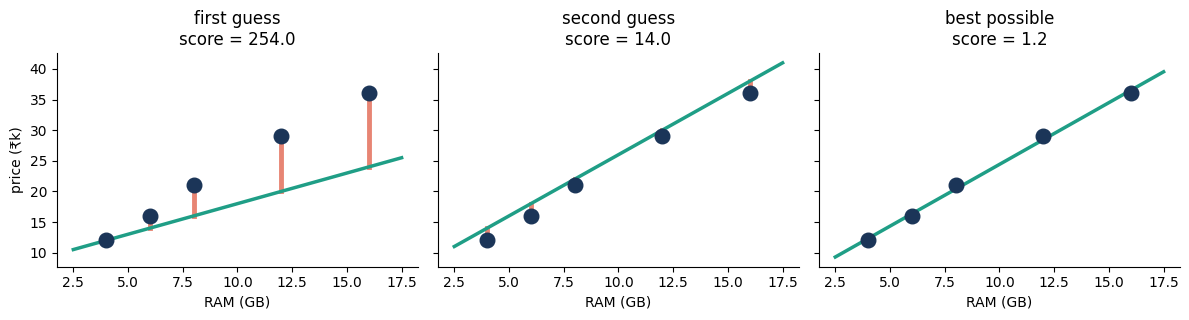

first guess     A=8.0     B=1.0     score 254.00
second guess    A=6.0     B=2.0     score 14.00
best possible   A=4.241   B=2.017   score 1.17


In [8]:
attempts = [(8.0, 1.0, "first guess"), (6.0, 2.0, "second guess"), (4.241, 2.017, "best possible")]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
smooth = np.linspace(2.5, 17.5, 40)

for ax, (A, B, name) in zip(axes, attempts):
    guesses = guess_price(A, B, ram)
    for r_, p_, g_ in zip(ram, price, guesses):
        ax.plot([r_, r_], [p_, g_], lw=3.5, color="#E05C45", alpha=.75)
    ax.plot(smooth, guess_price(A, B, smooth), lw=2.5, color="#1F9E86")
    ax.scatter(ram, price, s=110, color="#1B3558", zorder=4)
    ax.set_title(f"{name}\nscore = {how_wrong(A, B):.1f}", fontsize=12)
    ax.set_xlabel("RAM (GB)")
axes[0].set_ylabel("price (₹k)")
plt.tight_layout(); plt.show()

for A, B, name in attempts:
    print(f"{name:<15} A={A:<7} B={B:<7} score {how_wrong(A, B):.2f}")

**254 → 14 → 1.2.** The red bars get shorter every time.

That is it. That is "learning". A computer does this thousands of times a second, and it
does not need to be clever about it — it just keeps nudging A and B in whichever direction
makes the score smaller.

### And the computer finds those numbers for us

In [9]:
model = LinearRegression().fit(ram.reshape(-1, 1), price)

print(f"B (how much each GB adds) = {model.coef_[0]:.3f}")
print(f"A (the starting point)    = {model.intercept_:.3f}")
print(f"score                     = {how_wrong(model.intercept_, model.coef_[0]):.3f}")

B (how much each GB adds) = 2.017
A (the starting point)    = 4.241
score                     = 1.172


Exactly the "best possible" numbers from the third picture. **Every model in this course
works this way.** Only the shape of the guess changes.

## 2.4 · The most important rule in machine learning

Here is a question worth thinking about for a moment.

> A student memorises last year's question paper word for word and scores 100%.
> **Did they learn anything?**

No. And we can make exactly the same mistake with a model.

In [11]:
# 30 students: hours studied, and the marks they got
rng = np.random.default_rng(31)
hours = rng.uniform(0, 10, 30)
marks = 35 + 5.2 * hours + rng.normal(0, 6, 30)

# HIDE about a third of them. The model will never see these rows.
h_study, h_hidden, m_study, m_hidden = train_test_split(
    hours.reshape(-1, 1), marks, test_size=0.35, random_state=0)

print("rows the model may study :", len(h_study))
print("rows we are hiding       :", len(h_hidden))

rows the model may study : 19
rows we are hiding       : 11


In [12]:
line      = LinearRegression().fit(h_study, m_study)
staircase = DecisionTreeRegressor(random_state=0).fit(h_study, m_study)

print(f"{'':<12} {'studied rows':>14} {'HIDDEN rows':>14}")
print("-" * 42)
print(f"{'the line':<12} {line.score(h_study, m_study):>14.3f} {line.score(h_hidden, m_hidden):>14.3f}")
print(f"{'the tree':<12} {staircase.score(h_study, m_study):>14.3f} {staircase.score(h_hidden, m_hidden):>14.3f}")

               studied rows    HIDDEN rows
------------------------------------------
the line              0.925          0.840
the tree              1.000          0.644


*(These scores run from 0 to 1. Closer to 1 is better — we will define them properly later
in the module. For now just read them as "how well did it do".)*

Look at the tree. **A perfect 1.000 on the rows it studied, and 0.644 on rows it had never
seen.** It did not learn anything. It memorised.

The line scored slightly worse on the studied rows (0.925) and far better on the new ones
(0.840). **It learned the pattern instead of the answers.**

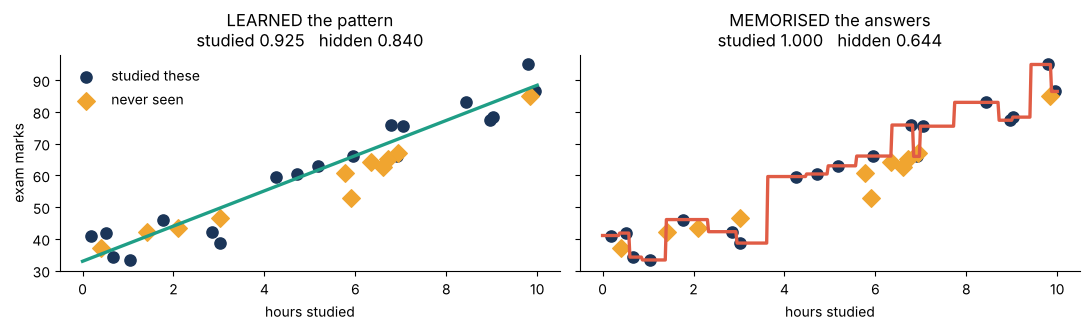

In [13]:
smooth = np.linspace(0, 10, 400).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)

for ax, (name, mdl, colr) in zip(axes, [("LEARNED the pattern", line, "#1F9E86"),
                                        ("MEMORISED the answers", staircase, "#E05C45")]):
    ax.plot(smooth, mdl.predict(smooth), lw=2.4, color=colr)
    ax.scatter(h_study, m_study, s=65, color="#1B3558", label="studied these")
    ax.scatter(h_hidden, m_hidden, s=80, color="#F0A530", marker="D", label="never seen")
    ax.set_title(f"{name}\nstudied {mdl.score(h_study,m_study):.3f}   "
                 f"hidden {mdl.score(h_hidden,m_hidden):.3f}", fontsize=12)
    ax.set_xlabel("hours studied")
axes[0].set_ylabel("exam marks"); axes[0].legend(frameon=False, fontsize=10)
plt.tight_layout(); plt.show()

The staircase goes up and down to touch every single studied point. That is the picture of
memorising, and it has a name: **overfitting**.

### The rule, with no exceptions

> **A score measured on rows the model has already seen is worth nothing.**

So from now on, every single time: **hide some rows first, train on the rest, report the
score on the hidden ones.**

## 2.5 · The eight steps of a real project

| Step | What happens |
|---|---|
| 1 | Collect the data |
| 2 | Clean it up |
| **3** | **Turn words into numbers**  ← the second half of today |
| 4 | Pick which features to use |
| 5 | Hide some rows |
| 6 | Train the model |
| 7 | Score it on the hidden rows |
| 8 | Use it on genuinely new data |

Most people imagine the job is step 6. In reality **steps 1 and 2 take most of the time**,
and step 6 is often three lines of code.

---
# Part 3 · The three families

Every machine learning problem belongs to one of three groups, and you tell them apart
with **one question: do we already have the answers?**

| Family | Do we have answers? | Example |
|---|---|---|
| **Supervised** | Yes | 1,000 emails already marked spam or not spam |
| **Unsupervised** | No | 10,000 customers nobody has sorted into groups |
| **Reinforcement** | No, but there is a score | A game that gives you points when you win |

Almost everything in this course is **supervised**, so let us look closer at that one.

## 3.1 · Supervised splits in two

It depends on what kind of answer you want back.

| | The answer is… | Examples |
|---|---|---|
| **Regression** | a **number** | price of a laptop · minutes to deliver · marks in an exam |
| **Classification** | a **group** | spam or not · pass or fail · which digit is in this photo |

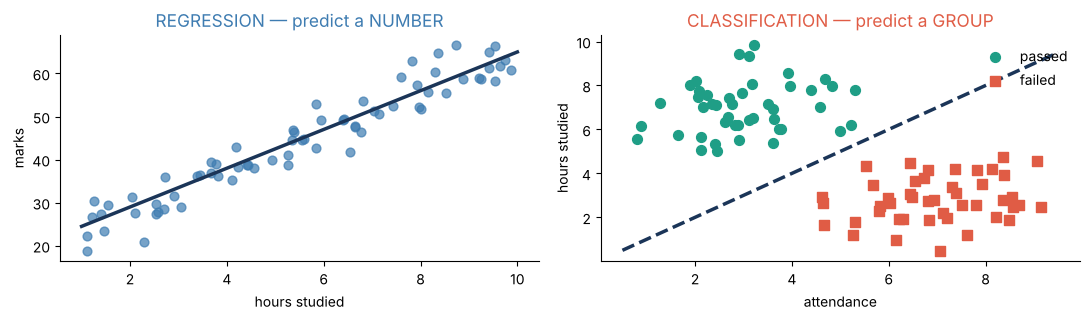

In [14]:
rng = np.random.default_rng(3101)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))

# regression - the answer is a number
xx = rng.uniform(1, 10, 70); yy = 20 + 4.5*xx + rng.normal(0, 4, 70)
axes[0].scatter(xx, yy, s=40, color="#3E7CB1", alpha=.7)
axes[0].plot(np.linspace(1,10,20), 20 + 4.5*np.linspace(1,10,20), lw=2.5, color="#1B3558")
axes[0].set_title("REGRESSION — predict a NUMBER", fontsize=12.5, color="#3E7CB1")
axes[0].set_xlabel("hours studied"); axes[0].set_ylabel("marks")

# classification - the answer is a group
a = rng.normal([3, 7], 1.1, (45, 2)); b = rng.normal([7, 3], 1.1, (45, 2))
axes[1].scatter(a[:,0], a[:,1], s=50, color="#1F9E86", label="passed")
axes[1].scatter(b[:,0], b[:,1], s=50, color="#E05C45", marker="s", label="failed")
axes[1].plot([0.5, 9.5], [0.5, 9.5], lw=2.5, color="#1B3558", ls="--")
axes[1].legend(frameon=False, fontsize=10)
axes[1].set_title("CLASSIFICATION — predict a GROUP", fontsize=12.5, color="#E05C45")
axes[1].set_xlabel("attendance"); axes[1].set_ylabel("hours studied")

plt.tight_layout(); plt.show()

## 3.2 · Naming any problem you meet

Two questions, in this order:

1. **Do we already have the answers for some rows?**
   - No → is there a score to chase? Yes → *reinforcement*. No → *unsupervised*.
   - Yes → go to question 2.
2. **Is the answer a number or a group?**
   - Number → *regression*
   - Group → *classification*

Try it on these.

| The problem | Answers? | Number or group? | So it is… |
|---|---|---|---|
| Predict a flat's rent from its size | Yes | Number | Supervised · **Regression** |
| Decide if a transaction is fraud | Yes | Group | Supervised · **Classification** |
| Split 10,000 shoppers into types | No | — | **Unsupervised** |
| Teach a robot arm to pick up a cup | No, but it gets a score | — | **Reinforcement** |
| Guess how long a delivery will take | Yes | Number | Supervised · **Regression** |
| Read the digit in a photo | Yes | Group | Supervised · **Classification** |

Notice how many are supervised. That is where this whole module lives.

---
# Part 4 · Words into numbers

Here is a problem nobody warns you about. **A model can only add and multiply.** And half
of every real dataset is words.

## 4.1 · Watch it break

In [15]:
small = pd.DataFrame({"ram_gb": [8, 16, 8], "brand": ["Dell", "HP", "Apple"]})
target = [34, 52, 71]

try:
    LinearRegression().fit(small, target)
except Exception as e:
    print(type(e).__name__, ":", e)

ValueError : could not convert string to float: 'Dell'


### Why it cannot work

Every model works by multiplying its inputs by weights:

    price  =  w1 × brand  +  w2 × ram

There is simply no answer to **"Dell × 0.4"**. This is not a limitation we can argue with.

**So every word in your data must become a number before anything else can happen.**

## 4.2 · The obvious idea — just number them

Apple=0, Asus=1, Dell=2, HP=3, Lenovo=4. Simple. And **wrong**.

In [13]:
brands = ["Apple", "Asus", "Dell", "HP", "Lenovo"]
numbering = {b: i for i, b in enumerate(brands)}
print(numbering)

{'Apple': 0, 'Asus': 1, 'Dell': 2, 'HP': 3, 'Lenovo': 4}


Look at what we have accidentally told the model:

- Lenovo (4) is **four times** Apple (0)
- HP (3) sits exactly **halfway** between Dell (2) and Lenovo (4)
- Asus (1) + Dell (2) = HP (3)

**Every one of those is nonsense.** Brands have no order. But nothing in the code warns
you — the model simply believes the ladder is real and builds its whole answer on it.

## 4.3 · Let us measure what that costs

600 laptops. We predict the price from RAM and brand. We change **nothing** except how the
brand column is turned into numbers.

In [14]:
rng = np.random.default_rng(310)
N = 600

brand_col = rng.choice(["Apple", "Asus", "Dell", "HP", "Lenovo"], N, p=[.18,.18,.24,.22,.18])
premium   = pd.Series(brand_col).map({"Apple":52, "Asus":4, "Dell":10, "HP":8, "Lenovo":6}).values
ram_col   = rng.choice([4, 8, 16, 32], N)
price_col = 18 + 1.5*ram_col + premium + rng.normal(0, 4, N)

shop = pd.DataFrame({"ram": ram_col, "brand": brand_col, "price": price_col})
shop.round(1).head()

,ram,brand,price
0,4,Dell,33.3
1,4,Lenovo,31.7
2,32,HP,80.6
3,32,HP,74.6
4,32,Asus,69.7


In [15]:
# VERSION 1 - just number the brands
v1 = shop.copy()
v1["brand"] = v1["brand"].map(numbering)
v1.round(1).head(3)

,ram,brand,price
0,4,2,33.3
1,4,4,31.7
2,32,3,80.6


In [16]:
# VERSION 2 - one yes/no column per brand  ("one-hot")
v2 = pd.get_dummies(shop, columns=["brand"], dtype=int)
v2.round(1).head(3)

,ram,price,brand_Apple,brand_Asus,brand_Dell,brand_HP,brand_Lenovo
0,4,33.3,0,0,1,0,0
1,4,31.7,0,0,0,0,1
2,32,80.6,0,0,0,1,0


In [17]:
for name, table in [("just numbering", v1), ("one-hot       ", v2)]:
    X = table.drop(columns=["price"])
    y = table["price"]
    X_study, X_hidden, y_study, y_hidden = train_test_split(X, y, test_size=.3, random_state=0)
    m = LinearRegression().fit(X_study, y_study)
    guesses = m.predict(X_hidden)
    print(f"{name}:  average error ₹{mean_absolute_error(y_hidden, guesses):5.2f}k   "
          f"score {m.score(X_hidden, y_hidden):.3f}")

just numbering:  average error ₹10.24k   score 0.642
one-hot       :  average error ₹ 3.34k   score 0.960


### The average error TRIPLED

**₹3,340 → ₹10,240**, purely because the brands were put in a false order. The score
dropped from 0.960 to 0.642.

Same data. Same model. Same RAM column. Only the encoding changed.

## 4.4 · One-hot encoding, step by step

Look again at what `get_dummies` did. One column of words became **one yes/no column per
brand**.

In [18]:
tiny = pd.DataFrame({"brand": ["Dell", "HP", "Apple", "Dell"]})
print("BEFORE:")
print(tiny.to_string(index=False))
print()
print("AFTER:")
print(pd.get_dummies(tiny, columns=["brand"], dtype=int).to_string(index=False))

BEFORE:
brand
 Dell
   HP
Apple
 Dell

AFTER:
 brand_Apple  brand_Dell  brand_HP
           0           1         0
           0           0         1
           1           0         0
           0           1         0


**Exactly one 1 in every row**, and no brand is bigger than any other — which is the truth.

That is one-hot encoding, and it is **your default choice** whenever the words have no
natural order.

### The whole thing is one line

In [22]:
encoded = pd.get_dummies(shop, columns=["brand"], dtype=int)

print("before:", list(shop.columns))
print("after :", list(encoded.columns))

before: ['ram', 'brand', 'price']
after : ['ram', 'price', 'brand_Apple', 'brand_Asus', 'brand_Dell', 'brand_HP', 'brand_Lenovo']


## 4.5 · Sometimes numbering IS correct

Ask yourself one question:

> **Is one of these genuinely MORE than another?**

- **Dell, HP, Apple** → no. They are just different. → **one-hot**
- **Small, Medium, Large** → yes! Large really is more than Small. → **just number them**

Let us check that on 500 coffee orders.

In [23]:
rng = np.random.default_rng(311)
M = 500
size = rng.choice(["Small", "Medium", "Large"], M)
ml   = pd.Series(size).map({"Small": 200, "Medium": 300, "Large": 400}).values
cost = 40 + 0.22 * ml + rng.normal(0, 6, M)

size_order = {"Small": 1, "Medium": 2, "Large": 3}
numbered = pd.Series(size).map(size_order).values.reshape(-1, 1)
one_hot  = pd.get_dummies(pd.DataFrame({"size": size}), columns=["size"]).values.astype(float)

for name, X in [("numbered 1,2,3  (1 column) ", numbered),
                ("one-hot         (3 columns)", one_hot)]:
    a, b, c, d = train_test_split(X, cost, test_size=.3, random_state=0)
    m = LinearRegression().fit(a, c)
    print(f"{name}:  average error ₹{mean_absolute_error(d, m.predict(b)):.2f}")

numbered 1,2,3  (1 column) :  average error ₹5.25
one-hot         (3 columns):  average error ₹5.25


**Identical — ₹5.25 either way.** But numbering used **one column instead of three**.

When the order is real, numbering is simpler and just as good. When it is not real, it is a
disaster. The only thing that decides it is the meaning of your data, which is why *you*
have to make this call, not the computer.

## 4.6 · ⚠️ When one-hot goes wrong

One-hot makes one column per category. So what happens with a column that has hundreds of
different values?

In [24]:
rng = np.random.default_rng(312)
K = 900
pincode = rng.integers(400001, 400001 + 520, K).astype(str)
value   = rng.normal(50, 10, K)

print(f"{K} delivery rows")
print(f"{len(set(pincode))} different pincodes")

wide = pd.get_dummies(pd.DataFrame({"pincode": pincode}), columns=["pincode"])
print(f"-> {wide.shape[1]} columns after one-hot encoding")

900 delivery rows
426 different pincodes
-> 426 columns after one-hot encoding


In [25]:
X = wide.values.astype(float)
X_study, X_hidden, y_study, y_hidden = train_test_split(X, value, test_size=.3, random_state=0)
m = LinearRegression().fit(X_study, y_study)

print(f"score on studied rows : {m.score(X_study, y_study):+.3f}")
print(f"score on HIDDEN rows  : {m.score(X_hidden, y_hidden):+.3f}")

score on studied rows : +0.561
score on HIDDEN rows  : -0.494


**426 columns from 900 rows.** Almost one column per row. Most pincodes appear once or
twice, so the model simply remembers each row rather than learning anything — and on new
rows it scores **−0.494**, which is worse than guessing.

### The fix: group the rare ones together

In [26]:
counts = pd.Series(pincode).value_counts()
top10 = counts.head(10).index

grouped = pd.Series(pincode).where(pd.Series(pincode).isin(top10), "OTHER")
print("different values now:", grouped.nunique())
print(grouped.value_counts().head(4).to_string())
print()
print("11 columns instead of 426.")

different values now: 11
OTHER     841
400292      8
400418      7
400233      7

11 columns instead of 426.


## 4.7 · Which encoding should I use?

| Your column looks like… | Example | Use this |
|---|---|---|
| Words with **no** order | brand, city, colour | **one-hot** |
| Words **with** a real order | Small / Medium / Large | **number them 1, 2, 3** |
| Only two options | yes / no | **one column of 0 and 1** |
| Hundreds of options | pincode, product ID | **group the rare ones first** |

**When you are unsure, use one-hot.** It is never *wrong* — it just costs extra columns.

---
# Part 5 · The whole thing, in one program

Everything from today, start to finish.

In [19]:
# ---- STEP 3 : turn the word column into numbers ----
data = pd.get_dummies(shop, columns=["brand"], dtype=int)

# ---- STEP 4 : separate the inputs from the answer ----
X = data.drop(columns=["price"])      # everything we know
y = data["price"]                     # what we want to predict

# ---- STEP 5 : hide 30% of the rows ----
X_study, X_hidden, y_study, y_hidden = train_test_split(
    X, y, test_size=0.3, random_state=0)

# ---- STEP 6 : train ----
model = LinearRegression().fit(X_study, y_study)

# ---- STEP 7 : score it on rows it has never seen ----
print(f"score on hidden rows : {model.score(X_hidden, y_hidden):.3f}")
print(f"average error        : ₹{mean_absolute_error(y_hidden, model.predict(X_hidden)):.2f}k")

score on hidden rows : 0.960
average error        : ₹3.34k


### Four things in that code worth remembering

| Line | Why it matters |
|---|---|
| `pd.get_dummies(...)` **first** | Words must become numbers before anything else works |
| `.drop(columns=["price"])` | If the answer stays among the inputs, the model just copies it |
| `random_state=0` | Makes the split identical every run, so your results repeat |
| `.score(X_hidden, ...)` | The only number worth reporting |

### And we can look inside the model

In [28]:
for feature, weight in zip(X.columns, model.coef_):
    print(f"  {feature:<16} {weight:+8.2f}")
print(f"  {'(starting point)':<16} {model.intercept_:+8.2f}")

  ram                 +1.50
  brand_Apple        +35.96
  brand_Asus         -11.03
  brand_Dell          -6.37
  brand_HP            -7.92
  brand_Lenovo       -10.64
  (starting point)   +34.36


Read the brand weights. The model worked out on its own that **Apple commands a large
premium** and the others sit much closer together — which is exactly how we built the data.

It was never told that. It found it.

---
# Six mistakes everybody makes once

| # | The mistake | What you will see | The fix |
|---|---|---|---|
| 1 | Feeding words straight in | `could not convert string to float` | `pd.get_dummies` first |
| 2 | Numbering brands 0,1,2,3 | A model that thinks Lenovo is 4× Apple | one-hot instead |
| 3 | Scoring on studied rows | A great score that collapses in real use | Always hide rows first |
| 4 | Leaving the answer in X | A suspiciously perfect score | `drop` the label column |
| 5 | One-hot on 400 pincodes | 400 new columns and pure memorising | Group the rare ones |
| 6 | Forgetting `random_state` | A different score every run | Set `random_state=0` |

Numbers 1, 2 and 5 are the same mistake underneath: forgetting that **the model only ever
sees numbers, never meanings.**

---
# What to remember

| | |
|---|---|
| **The flip** | Ordinary code: you give rules, it gives answers. ML: you give answers, it finds the rules. |
| **A model is just numbers** | Training means nudging them until the error shrinks. We watched 254 → 14 → 1.2. |
| **Hide rows before training** | A score on rows already seen proves nothing. The tree scored 1.000 then 0.644. |
| **Three families** | Have the answers → supervised. No answers → unsupervised. Only a score → reinforcement. |
| **⚠️ Models cannot read words** | "Dell" must become a number before anything else happens. |
| **⚠️ Numbering brands is wrong** | It invents an order that does not exist. It tripled our error: ₹3.3k → ₹10.2k. |

### Homework

1. Find any table of data with at least one **word column** and one **number** you could
   try to predict.
2. Say in writing: what is a sample here, what are the features, what is the label?
3. Name the problem — supervised or unsupervised, regression or classification?
4. One-hot encode the word column and write down **how many columns** you ended up with.
   If it is more than about 15, say which ones you would group into "OTHER".

### Next

**Day 32 — getting those numbers into the right shape** before a model ever sees them.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*